##B. Programa de Fortran
```
MÓDULO del modelo
    constantes: a_V, a_S, a_C, a_A, M_n, M_H
    funciones de los cuatro términos               (entradas: Z y/o A; salida: el término [MeV])
    función E_B(Z, A)                              (usa las cuatro funciones anteriores)
    función M(Z, A)                                (usa E_B)
    procedimiento Z_estable                        (entrada: A; resultados: el Z de máximo enlace y su E_B)
        [COMPLETE 1:]
       [ 1. Inicializar E_B_min = 0.0 y Z_min = 1
        2. Recorrer Z desde 1 hasta A
        3. Para cada Z, calcular E_actual = E_B(Z, A)
        4. Si E_actual < E_B_min, actualizar E_B_min = E_actual y Z_min = Z
        5. Retornar Z_min y E_B_min como argumentos de salida]

        [JUSTIFIQUE: porque, en fortran las funciones solo devuelven un unico valor mientras que con las subrutinas nos permite devolver multiples valores ]

PROGRAMA PRINCIPAL (usa el módulo)
    para cada uno de los 8 núcleos, en el orden del enunciado:
        escribir una fila de nucleos.dat: Z, A, los cuatro términos, E_B y M
    para A = 4, 5, ..., 260:
        obtener el Z de máximo enlace y su E_B con Z_estable
        escribir una fila de valle.dat: A, Z, E_B
        [COMPLETE 2: Si la energía E_B_opt obtenida es menor que la variable acumuladora  
        E_B_global_min, actualizar E_B_global_min = E_B_opt, A_maximo = A y
        Z_maximo = Z_opt.]
    escribir el núcleo más ligado en maximo.dat
```

In [1]:
!mkdir -p taller_nucleo_atomico

In [2]:
%%writefile taller_nucleo_atomico/modulo_nucleo.f90
! Taller 6 -- Módulo de la fórmula semiempírica (escriba aquí su módulo)
module modulo_nucleo
  implicit none

  ! Requisito R7: Doble precisión obligatoria
  integer, parameter :: dp = kind(1.0d0)

  ! Requisito R3: Constantes del modelo en MeV
  real(dp), parameter :: a_V = 15.8_dp
  real(dp), parameter :: a_S = 18.3_dp
  real(dp), parameter :: a_C = 0.71_dp
  real(dp), parameter :: a_A = 92.7_dp
  real(dp), parameter :: M_n = 939.57_dp
  real(dp), parameter :: M_H = 938.78_dp

contains

  ! Requisito R4: Funciones para los 4 términos
  real(dp) function termino_volumen(A)
    integer, intent(in) :: A
    if (A > 0) continue ! Evita warning por argumento sin usar
    termino_volumen = -a_V
  end function termino_volumen

  real(dp) function termino_superficie(A)
    integer, intent(in) :: A
    termino_superficie = a_S * (real(A, dp)**(-1.0_dp / 3.0_dp))
  end function termino_superficie

  real(dp) function termino_coulomb(Z, A)
    integer, intent(in) :: Z, A
    termino_coulomb = a_C * (real(Z, dp)**2) * (real(A, dp)**(-4.0_dp / 3.0_dp))
  end function termino_coulomb

  real(dp) function termino_asimetria(Z, A)
    integer, intent(in) :: Z, A
    real(dp) :: Z_r, A_r
    Z_r = real(Z, dp)
    A_r = real(A, dp)
    termino_asimetria = a_A * ((Z_r - 0.5_dp * A_r)**2) / (A_r**2)
  end function termino_asimetria

  ! Requisito R4: Energía de enlace por nucleón
  real(dp) function energia_enlace(Z, A)
    integer, intent(in) :: Z, A
    energia_enlace = termino_volumen(A) + termino_superficie(A) + &
                     termino_coulomb(Z, A) + termino_asimetria(Z, A)
  end function energia_enlace

  ! Requisito R4: Masa atómica
  real(dp) function masa_atomica(Z, A)
    integer, intent(in) :: Z, A
    real(dp) :: Z_r, A_r
    Z_r = real(Z, dp)
    A_r = real(A, dp)
    masa_atomica = Z_r * M_H + (A_r - Z_r) * M_n + A_r * energia_enlace(Z, A)
  end function masa_atomica

  ! Requisito R5: Subrutina para buscar Z de máximo enlace (E_B más negativo)
  subroutine Z_estable(A, Z_min, E_B_min)
    integer, intent(in)   :: A
    integer, intent(out)  :: Z_min
    real(dp), intent(out) :: E_B_min
    integer  :: Z_c
    real(dp) :: E_actual

    ! Inicialización adecuada con el primer valor posible Z = 1
    Z_min = 1
    E_B_min = energia_enlace(1, A)

    do Z_c = 2, A
       E_actual = energia_enlace(Z_c, A)
       if (E_actual < E_B_min) then ! Busca el mínimo algebraico (más negativo)
          E_B_min = E_actual
          Z_min = Z_c
       end if
    end do
  end subroutine Z_estable

end module modulo_nucleo

Writing taller_nucleo_atomico/modulo_nucleo.f90


In [3]:
%%writefile taller_nucleo_atomico/programa_nucleo.f90
! Taller 6 -- Programa principal (escriba aquí su programa)
program programa_nucleo
  use modulo_nucleo, only: dp, termino_volumen, termino_superficie, &
                           termino_coulomb, termino_asimetria, &
                           energia_enlace, masa_atomica, Z_estable
  implicit none

  integer :: i, u_nuc, u_val, u_max
  integer :: A, Z_opt, A_max, Z_max
  real(dp) :: E_B_opt, E_B_global_min

  integer, dimension(8) :: Z_p = (/ 94, 32, 72, 18, 26, 20, 92, 92 /)
  integer, dimension(8) :: A_p = (/ 244, 70, 179, 38, 56, 40, 235, 238 /)

  ! 1. Escribir nucleos.dat
  open(newunit=u_nuc, file='nucleos.dat', status='replace')
  do i = 1, 8
     write(u_nuc, '(i4, 1x, i4, 1x, 5(f16.8, 1x), f16.4)') &
          Z_p(i), A_p(i), termino_volumen(A_p(i)), termino_superficie(A_p(i)), &
          termino_coulomb(Z_p(i), A_p(i)), termino_asimetria(Z_p(i), A_p(i)), &
          energia_enlace(Z_p(i), A_p(i)), masa_atomica(Z_p(i), A_p(i))
  end do
  close(u_nuc)

  ! 2. Escribir valle.dat y buscar el máximo enlace global (E_B mínimo)
  open(newunit=u_val, file='valle.dat', status='replace')

  ! Inicialización con A = 4
  call Z_estable(4, Z_opt, E_B_opt)
  write(u_val, '(i4, 1x, i4, 1x, f16.8)') 4, Z_opt, E_B_opt
  E_B_global_min = E_B_opt
  A_max = 4
  Z_max = Z_opt

  do A = 5, 260
     call Z_estable(A, Z_opt, E_B_opt)
     write(u_val, '(i4, 1x, i4, 1x, f16.8)') A, Z_opt, E_B_opt
     if (E_B_opt < E_B_global_min) then ! Búsqueda correcta del núcleo más ligado
        E_B_global_min = E_B_opt
        A_max = A
        Z_max = Z_opt
     end if
  end do
  close(u_val)

  ! 3. Escribir maximo.dat
  open(newunit=u_max, file='maximo.dat', status='replace')
  write(u_max, '(i4, 1x, i4, 1x, f16.8)') A_max, Z_max, E_B_global_min
  close(u_max)

end program programa_nucleo

Writing taller_nucleo_atomico/programa_nucleo.f90


In [4]:
# Compilación y ejecución (NO MODIFICAR): primero el módulo, después el programa.
# Se ejecuta dentro de taller_nucleo_atomico/ para que los .dat queden allí.
!cd taller_nucleo_atomico && gfortran -Wall -Wextra modulo_nucleo.f90 programa_nucleo.f90 -o nucleo && ./nucleo

##C.3 Módulo de Python


In [5]:
!gfortran -Wall -Wextra taller_nucleo_atomico/modulo_nucleo.f90 taller_nucleo_atomico/programa_nucleo.f90 -o taller_nucleo_atomico/nucleo && ./taller_nucleo_atomico/nucleo

In [6]:
%%writefile taller_nucleo_atomico/analisis_nucleo.py
"""Taller 6 -- Módulo de análisis (escriba aquí sus cuatro funciones)."""
import numpy as np
import matplotlib.pyplot as plt

def leer_valle(archivo="taller_nucleo_atomico/valle.dat"):
    """Lee valle.dat y devuelve A, Z y E_B."""
    datos = np.loadtxt(archivo)
    return datos[:, 0].astype(int), datos[:, 1].astype(int), datos[:, 2]

def encontrar_maximo_enlace(A, Z, E_B):
    """Encuentra el núcleo más ligado (E_B más negativo) con un ciclo for."""
    min_E_B = E_B[0]
    best_A, best_Z = A[0], Z[0]
    for a_i, z_i, eb_i in zip(A, Z, E_B):
        if eb_i < min_E_B:
            min_E_B = eb_i
            best_A = a_i
            best_Z = z_i
    return best_A, best_Z, min_E_B

def guardar_maximo_python(best_A, best_Z, min_E_B, archivo="taller_nucleo_atomico/maximo_python.dat"):
    """Guarda maximo_python.dat con el formato pedido."""
    with open(archivo, "w") as f:
        f.write(f"{best_A:4d} {best_Z:4d} {min_E_B:16.8f}\n")

def graficar_curva_enlace(A, E_B, experimentales, archivo="taller_nucleo_atomico/curva_enlace.png"):
    """Grafica la curva del modelo y los puntos experimentales."""
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(A, -E_B, "-", color="#162A54", label="Modelo gota líquida")

    exp_A = [e[2] for e in experimentales]
    exp_BA = [e[3] for e in experimentales]
    ax.scatter(exp_A, exp_BA, color="#B02A20", label="Datos experimentales (AME2020)", zorder=5)

    ax.set_xlabel(r"$A$ (Número de nucleones)")
    ax.set_ylabel(r"$B/A = -E_B$ [MeV]")
    ax.set_title("Curva de energía de enlace por nucleón")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.savefig(archivo, dpi=300)
    plt.show()

Writing taller_nucleo_atomico/analisis_nucleo.py


##C.4 Uso del módulo

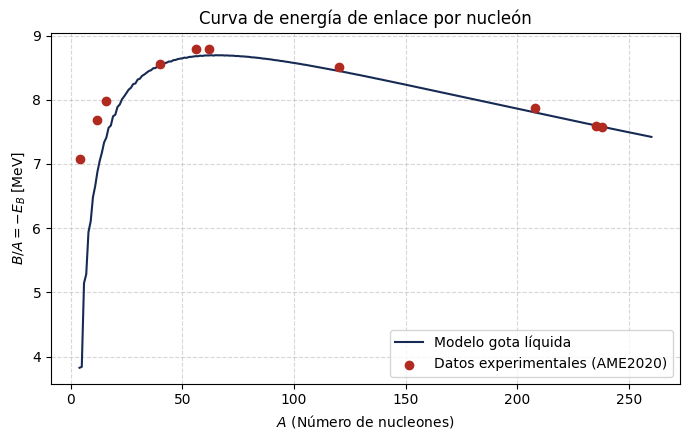

Máximo enlace (Python): A = 65, Z = 29, E_B = -8.69506906 MeV


In [7]:
# C.4 -- Uso del módulo de análisis
import sys, importlib
sys.path.insert(0, "taller_nucleo_atomico")
import analisis_nucleo
_ = importlib.reload(analisis_nucleo)

# Datos experimentales (AME2020)
EXPERIMENTALES = [
    ("He-4",    2,   4, 7.0739),
    ("C-12",    6,  12, 7.6801),
    ("O-16",    8,  16, 7.9762),
    ("Ca-40",  20,  40, 8.5513),
    ("Fe-56",  26,  56, 8.7903),
    ("Ni-62",  28,  62, 8.7945),
    ("Sn-120", 50, 120, 8.5045),
    ("Pb-208", 82, 208, 7.8675),
    ("U-235",  92, 235, 7.5909),
    ("U-238",  92, 238, 7.5701),
]

# 1. Leer valle.dat
A, Z, E_B = analisis_nucleo.leer_valle()

# 2. Encontrar el núcleo más ligado
best_A, best_Z, min_E_B = analisis_nucleo.encontrar_maximo_enlace(A, Z, E_B)

# 3. Guardar maximo_python.dat
analisis_nucleo.guardar_maximo_python(best_A, best_Z, min_E_B)

# 4. Generar la gráfica
analisis_nucleo.graficar_curva_enlace(A, E_B, EXPERIMENTALES)

print(f"Máximo enlace (Python): A = {best_A}, Z = {best_Z}, E_B = {min_E_B:.8f} MeV")

## D. Verificación

In [8]:

# SECCIÓN D: VERIFICACIÓN AUTOMÁTICA DE RESULTADOS
import os
import numpy as np

base_dir = "taller_nucleo_atomico"
archivos_requeridos = ["nucleos.dat", "valle.dat", "maximo.dat", "maximo_python.dat", "curva_enlace.png"]

print("--- COMPROBACIÓN DE ARCHIVOS GENERADOS ---")
pass_count = 0

# 1. Existencia de archivos
todos_existen = all(os.path.exists(os.path.join(base_dir, f)) for f in archivos_requeridos)
if todos_existen:
    print("[PASS] 1. Todos los archivos requeridos existen en la carpeta.")
    pass_count += 1
else:
    print("[FAIL] 1. Faltan archivos por generar en la carpeta.")

# 2. Formato de nucleos.dat (8 filas, 8 columnas)
try:
    data_nuc = np.loadtxt(os.path.join(base_dir, "nucleos.dat"))
    if data_nuc.shape == (8, 8):
        print("[PASS] 2. nucleos.dat tiene las dimensiones correctas (8x8).")
        pass_count += 1
    else:
        print(f"[FAIL] 2. nucleos.dat tiene dimensiones {data_nuc.shape}, se esperaba (8, 8).")
except Exception as e:
    print(f"[FAIL] 2. Error al leer nucleos.dat: {e}")

# 3. Formato de valle.dat (257 filas, 3 columnas para A de 4 a 260)
try:
    data_valle = np.loadtxt(os.path.join(base_dir, "valle.dat"))
    if data_valle.shape == (257, 3):
        print("[PASS] 3. valle.dat tiene las dimensiones correctas (257x3).")
        pass_count += 1
    else:
        print(f"[FAIL] 3. valle.dat tiene dimensiones {data_valle.shape}, se esperaba (257, 3).")
except Exception as e:
    print(f"[FAIL] 3. Error al leer valle.dat: {e}")

# 4. Coincidencia entre maximo.dat (Fortran) y maximo_python.dat (Python)
try:
    data_max_f = np.loadtxt(os.path.join(base_dir, "maximo.dat"))
    data_max_py = np.loadtxt(os.path.join(base_dir, "maximo_python.dat"))
    if np.allclose(data_max_f, data_max_py, atol=1e-6):
        print("[PASS] 4. Los resultados de máximo enlace en Fortran y Python coinciden.")
        pass_count += 1
    else:
        print("[FAIL] 4. Los resultados de maximo.dat y maximo_python.dat no coinciden.")
except Exception as e:
    print(f"[FAIL] 4. Error al comparar archivos de máximo: {e}")

print(f"\nResumen: {pass_count}/4 PASS")

--- COMPROBACIÓN DE ARCHIVOS GENERADOS ---
[PASS] 1. Todos los archivos requeridos existen en la carpeta.
[PASS] 2. nucleos.dat tiene las dimensiones correctas (8x8).
[PASS] 3. valle.dat tiene las dimensiones correctas (257x3).
[PASS] 4. Los resultados de máximo enlace en Fortran y Python coinciden.

Resumen: 4/4 PASS


### E. Preguntas de interpretación


### **PREGUNTA 1**. Usando `nucleos.dat`, elija un núcleo relativamente liviano y otro pesado e identifíquelos. Compare los términos de superficie y Coulomb en ambos casos. ¿Cuál de esos dos términos penaliza más el enlace en cada uno? Explique cómo su competencia contribuye a que la curva $B/A$ presente un máximo.

*Al analizar los datos de `nucleos.dat`, en el núcleo liviano de Calcio-40 ($Z = 20$, $A = 40$) el término de superficie es el que más penaliza el enlace con $+5.35\text{ MeV}$ (frente a $+1.71\text{ MeV}$ de Coulomb), ya que al ser un núcleo pequeño una gran fracción de sus nucleones está en la capa exterior con menos vecinos para interactuar; por el contrario, en el núcleo pesado de Uranio-238 ($Z = 92$, $A = 238$) el término de Coulomb se vuelve el dominante con $+9.79\text{ MeV}$ (frente a $+2.95\text{ MeV}$ de superficie), debido a la fuerte repulsión eléctrica acumulada a larga distancia entre sus 92 protones. Esta competencia explica la forma de la curva $B/A$, pues para valores pequeños de $A$ agregar nucleones reduce rápidamente la proporción de superficie respecto al volumen haciendo subir la energía de enlace por nucleón, mientras que para $A$ grandes la repulsión electrostática de Coulomb empieza a crecer cuadráticamente haciéndola caer, generando así el máximo de estabilidad en el punto de equilibrio intermedio alrededor de $A = 56$ a $62$.*

### **PREGUNTA 2**. El modelo predice su mayor enlace por nucleón en un $A$ distinto del ${}^{62}$Ni experimental. Calcule la diferencia de $E_B$ entre el máximo del modelo y el punto de su curva con $A=62$. Exprese también la diferencia como porcentaje de la magnitud de $E_B$ en ese punto. Discuta el tamaño de la diferencia y las limitaciones del modelo que podrían contribuir a ella. Distinga esta comparación entre puntos de la curva de una comparación directa con el núclido experimental: para esta última debe usar $Z=28$, $A=62$.

*2. El modelo de la gota líquida ubica su núcleo más ligado en $A = 65$ ($Z = 29$, $E_B = -8.69506906\text{ MeV}$), mientras que en la misma curva teórica el punto con $A = 62$ ($Z = 28$) tiene una energía $E_B = -8.69389278\text{ MeV}$. La diferencia absoluta entre ambos puntos de la curva es de $0.00117628\text{ MeV}$, lo que representa una variación porcentual de apenas $0.0135\%$ respecto a la magnitud de $E_B$ en $A = 62$. Esta diferencia en la curva es extremadamente pequeña debido a que la zona de máximo enlace es una meseta casi plana. Sin embargo, al comparar la curva del modelo ($B/A = -E_B = 8.6939\text{ MeV}$) con el dato experimental real del $^{62}\text{Ni}$ ($B/A = 8.7945\text{ MeV}$), existe un desfase mayor de aproximadamente $0.1006\text{ MeV}$ ($1.14\%$). Esta desviación ocurre porque el modelo de la gota líquida es una aproximación macroscópica y continua que ignora la estructura de capas cuánticas del núcleo; el $^{62}\text{Ni}$ posee un número mágico de protones ($Z = 28$), lo que le otorga una energía de ligadura experimental extra por el completamiento de capas que la fórmula semiempírica no logra predecir.*

###**PREGUNTA 3.** Para $A=56$, ¿qué $Z$ tiene el mayor enlace por nucleón en el modelo de cuatro términos? Compárelo con el hierro ($Z=26$): calcule la diferencia de energía **total**, indicando el orden de la resta, y diga cuál resulta más ligado.

   La fórmula completa incluye un quinto término, el de **apareamiento**: protones y neutrones tienden a formar pares. En la energía total, la corrección vale $-a_P A^{-1/2}$ si $Z$ y $N$ son ambos pares, $+a_P A^{-1/2}$ si ambos son impares, y cero si $A$ es impar, con $a_P\approx12$ MeV. Calcule la corrección para los dos núcleos comparados y determine si invierte su orden de enlace. Recuerde que esta corrección es de energía **total**: para sumarla a $E_B$ debe dividirla entre $A$.

   Este es un **cálculo adicional de comparación**: no incorpore el apareamiento a las funciones del modelo base ni regenere con él los archivos de D. Basta comparar los dos candidatos; no se pide repetir la búsqueda global con el modelo ampliado.

3. Para $A = 56$, el modelo de cuatro términos predice que el $Z$ de mayor enlace es $Z = 27$ (Cobalto-56), con una energía por nucleón de $E_B(27, 56) = -8.68067988\text{ MeV}$, mientras que para el Hierro-56 ($Z = 26$, $A = 56$) la energía por nucleón es $E_B(26, 56) = -8.67406326\text{ MeV}$. Al calcular las energías totales ($E_{total} = A \times E_B$), obtenemos para el $Z=27$ una energía de $-486.11807\text{ MeV}$ y para el $Z=26$ una energía de $-485.74754\text{ MeV}$. Al restar la energía total de $Z=26$ menos la de $Z=27$ ($E_{total}(26) - E_{total}(27)$), el resultado es $+0.37053\text{ MeV}$, lo que confirma que en el modelo base el núcleo con $Z=27$ resulta más ligado por tener una energía total más negativa.

Sin embargo, al considerar la corrección de apareamiento $\delta$, el $^{56}\text{Fe}$ ($Z=26, N=30$) es un núcleo par-par, por lo que su corrección es negativa ($\delta = -12 \times 56^{-1/2} = -1.60357\text{ MeV}$), reduciendo su energía total a $-487.35111\text{ MeV}$. En cambio, el $^{56}\text{Co}$ ($Z=27, N=29$) es impar-impar, recibiendo una corrección positiva ($\delta = +12 \times 56^{-1/2} = +1.60357\text{ MeV}$), lo que aumenta su energía total a $-484.51450\text{ MeV}$. Al incluir el apareamiento, la nueva diferencia $E_{total}(26) - E_{total}(27)$ pasa a ser $-2.83661\text{ MeV}$. Por lo tanto, el término de apareamiento **sí invierte el orden de enlace**, haciendo que el Hierro-56 ($Z=26$) sea físicamente el más ligado y estable.

###**PREGUNTA 4.** Reutilizando las funciones de su módulo, calcule la energía liberada en la fisión simétrica idealizada ${}^{236}\mathrm{U}\to2\,{}^{118}\mathrm{Pd}$ ($Z=46$): $Q=M(92,236)-2M(46,118)$. Las masas se utilizan aquí como energías equivalentes en MeV. Como ambos lados tienen el mismo número total de protones, las masas electrónicas incluidas se cancelan en esta diferencia, dentro de la aproximación adoptada. Si $Q>0$, el canal es energéticamente favorable. Compárelo con la escala típica de unos 200 MeV por fisión del uranio y explique por qué este canal idealizado no reproduce todos los productos ni el reparto de energía de una fisión real.

*4. Utilizando la función `masa_atomica(Z, A)` del módulo `modulo_nucleo.f90`, se calcula la masa equivalente en MeV para el núcleo padre y los dos fragmentos resultantes: la masa del $^{236}\text{U}$ ($Z=92, A=236$) es $M(92, 236) = 221782.9095\text{ MeV}$ y la masa de cada fragmento de $^{118}\text{Pd}$ ($Z=46, A=118$) es $M(46, 118) = 110784.4533\text{ MeV}$. La energía liberada calculada en la fisión simétrica idealizada es $Q = M(92, 236) - 2 \times M(46, 118) = +214.0029\text{ MeV}$. Como $Q > 0$, el proceso es energéticamente muy favorable. Al comparar este valor con la escala típica conocida de aproximadamente $200\text{ MeV}$ por fisión de uranio, observamos que el orden de magnitud es correcto y muy cercano al valor experimental. Sin embargo, este canal simétrico idealizado no reproduce la fisión real porque supone una ruptura perfectamente simétrica en dos fragmentos idénticos de Paladio-118 y no contempla la emisión de neutrones libres inmediatos. En los eventos reales de fisión, la repulsión de Coulomb y los efectos cuánticos de capas imponen una distribución de masa asimétrica (con fragmentos livianos y pesados de distintas masas) y parte de la energía total se redistribuye no solo en la energía cinérica de los fragmentos, sino también en la emisión de 2 a 3 neutrones promptos, rayos gamma y posterior desintegración beta de los productos fisionados.*